# Projet 8 : Lapage - Analysez les ventes d'une librairie

## Partie 1 : Importation et nettoyage des données

### 1-1 : Importation des librairies et chargement des fichiers


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose, STL

In [2]:
#Importation du fichier customers.csv
customers = pd.read_csv("C:/Users/capel/Desktop/Data Analyst/Projet 8/DAN-P6-donnees/customers.csv")
#Importation du fichier products.csv
products = pd.read_csv("C:/Users/capel/Desktop/Data Analyst/Projet 8/DAN-P6-donnees/products.csv")
#Importation du fichier transactions.csv
transactions = pd.read_csv("C:/Users/capel/Desktop/Data Analyst/Projet 8/DAN-P6-donnees/transactions.csv")

### 1-2 : Analyse exploratoire des fichiers

#### 1-2-1 : Analyse de customers

In [3]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(customers.shape[1]))
#La nature des données dans chacune des colonnes
print("La nature des données dans chacune des colonnes est :")
print(customers.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
print("Le nombre de valeurs présentes dans chacune des colonnes est :")
print(pd.DataFrame(customers).count())

Le tableau comporte 3 colonne(s)
La nature des données dans chacune des colonnes est :
client_id    object
sex          object
birth         int64
dtype: object
Le nombre de valeurs présentes dans chacune des colonnes est :
client_id    8623
sex          8623
birth        8623
dtype: int64


In [4]:
customers.head()

,client_id,sex,birth
0,c_4410,f,1967
1,c_7839,f,1975
2,c_1699,f,1984
3,c_5961,f,1962
4,c_5320,m,1943


In [5]:
customers['client_id'].duplicated().sum()

np.int64(0)

In [6]:
customers.isnull().sum()

client_id    0
sex          0
birth        0
dtype: int64

In [7]:
customers.describe(include = 'all')

,client_id,sex,birth
count,8623,8623,8623.000000
unique,8623,2,NaN
top,c_4410,f,NaN
freq,1,4491,NaN
mean,NaN,NaN,1978.280877
std,NaN,NaN,16.919535
min,NaN,NaN,1929.000000
25%,NaN,NaN,1966.000000
50%,NaN,NaN,1979.000000
75%,NaN,NaN,1992.000000


#### 1-2-1 : Analyse de products


In [8]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(products.shape[1]))
#La nature des données dans chacune des colonnes
print("La nature des données dans chacune des colonnes est :")
print(products.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
print("Le nombre de valeurs présentes dans chacune des colonnes est :")
print(pd.DataFrame(products).count())

Le tableau comporte 3 colonne(s)
La nature des données dans chacune des colonnes est :
id_prod     object
price      float64
categ        int64
dtype: object
Le nombre de valeurs présentes dans chacune des colonnes est :
id_prod    3287
price      3287
categ      3287
dtype: int64


In [9]:
products.head()

,id_prod,price,categ
0,0_1421,19.99,0
1,0_1368,5.13,0
2,0_731,17.99,0
3,1_587,4.99,1
4,0_1507,3.99,0


In [10]:
products['id_prod'].duplicated().sum()

np.int64(0)

In [11]:
products.isnull().sum()

id_prod    0
price      0
categ      0
dtype: int64

In [12]:
products.describe(include = 'all')

,id_prod,price,categ
count,3287,3287.000000,3287.000000
unique,3287,NaN,NaN
top,0_1421,NaN,NaN
freq,1,NaN,NaN
mean,NaN,21.856641,0.370246
std,NaN,29.847908,0.615387
min,NaN,-1.000000,0.000000
25%,NaN,6.990000,0.000000
50%,NaN,13.060000,0.000000
75%,NaN,22.990000,1.000000


#### 1-2-1 : Analyse de transactions


In [13]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(transactions.shape[1]))
#La nature des données dans chacune des colonnes
print("La nature des données dans chacune des colonnes est :")
print(transactions.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
print("Le nombre de valeurs présentes dans chacune des colonnes est :")
print(pd.DataFrame(transactions).count())

Le tableau comporte 4 colonne(s)
La nature des données dans chacune des colonnes est :
id_prod       object
date          object
session_id    object
client_id     object
dtype: object
Le nombre de valeurs présentes dans chacune des colonnes est :
id_prod       679532
date          679532
session_id    679532
client_id     679532
dtype: int64


In [14]:
transactions.head()

,id_prod,date,session_id,client_id
0,0_1518,2022-05-20 13:21:29.043970,s_211425,c_103
1,1_251,2022-02-02 07:55:19.149409,s_158752,c_8534
2,0_1277,2022-06-18 15:44:33.155329,s_225667,c_6714
3,2_209,2021-06-24 04:19:29.835891,s_52962,c_6941
4,0_1509,2023-01-11 08:22:08.194479,s_325227,c_4232


In [15]:
transactions['id_prod'].duplicated().sum()

np.int64(676265)

In [16]:
transactions['session_id'].duplicated().sum()

np.int64(337216)

In [17]:
transactions['client_id'].duplicated().sum()

np.int64(670930)

In [18]:
transactions.isnull().sum()

id_prod       0
date          0
session_id    0
client_id     0
dtype: int64

In [19]:
transactions.describe(include = 'all')

,id_prod,date,session_id,client_id
count,679532,679532,679532,679532
unique,3267,679371,342316,8602
top,1_369,test_2021-03-01 02:30:02.237413,s_0,c_1609
freq,2252,13,200,25488


In [20]:
transactions[transactions["date"].astype(str).str.contains("test", na=False)]

,id_prod,date,session_id,client_id
3019,T_0,test_2021-03-01 02:30:02.237419,s_0,ct_0
5138,T_0,test_2021-03-01 02:30:02.237425,s_0,ct_0
9668,T_0,test_2021-03-01 02:30:02.237437,s_0,ct_1
10728,T_0,test_2021-03-01 02:30:02.237436,s_0,ct_0
15292,T_0,test_2021-03-01 02:30:02.237430,s_0,ct_0
...,...,...,...,...
657830,T_0,test_2021-03-01 02:30:02.237417,s_0,ct_0
662081,T_0,test_2021-03-01 02:30:02.237427,s_0,ct_1
670680,T_0,test_2021-03-01 02:30:02.237449,s_0,ct_1
671647,T_0,test_2021-03-01 02:30:02.237424,s_0,ct_1


### 1-3 : Jonction des fichiers

In [21]:
transactions_products = pd.merge(transactions, products, on='id_prod', how='left')

In [22]:
lapage = pd.merge(transactions_products, customers, on='client_id', how='left')

In [23]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(lapage.shape[1]))
#La nature des données dans chacune des colonnes
print("La nature des données dans chacune des colonnes est :")
print(lapage.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
print("Le nombre de valeurs présentes dans chacune des colonnes est :")
print(pd.DataFrame(lapage).count())

Le tableau comporte 8 colonne(s)
La nature des données dans chacune des colonnes est :
id_prod        object
date           object
session_id     object
client_id      object
price         float64
categ         float64
sex            object
birth           int64
dtype: object
Le nombre de valeurs présentes dans chacune des colonnes est :
id_prod       679532
date          679532
session_id    679532
client_id     679532
price         679311
categ         679311
sex           679532
birth         679532
dtype: int64


In [24]:
lapage.head()

,id_prod,date,session_id,client_id,price,categ,sex,birth
0,0_1518,2022-05-20 13:21:29.043970,s_211425,c_103,4.18,0.0,f,1986
1,1_251,2022-02-02 07:55:19.149409,s_158752,c_8534,15.99,1.0,m,1988
2,0_1277,2022-06-18 15:44:33.155329,s_225667,c_6714,7.99,0.0,f,1968
3,2_209,2021-06-24 04:19:29.835891,s_52962,c_6941,69.99,2.0,m,2000
4,0_1509,2023-01-11 08:22:08.194479,s_325227,c_4232,4.99,0.0,m,1980


In [25]:
lapage[lapage['price'].isna()]

,id_prod,date,session_id,client_id,price,categ,sex,birth
2633,0_2245,2022-09-23 07:22:38.636773,s_272266,c_4746,NaN,NaN,m,1940
10106,0_2245,2022-07-23 09:24:14.133889,s_242482,c_6713,NaN,NaN,f,1963
11727,0_2245,2022-12-03 03:26:35.696673,s_306338,c_5108,NaN,NaN,m,1978
15675,0_2245,2021-08-16 11:33:25.481411,s_76493,c_1391,NaN,NaN,m,1991
16377,0_2245,2022-07-16 05:53:01.627491,s_239078,c_7954,NaN,NaN,m,1973
...,...,...,...,...,...,...,...,...
669730,0_2245,2021-08-25 09:06:03.504061,s_80395,c_131,NaN,NaN,m,1981
670682,0_2245,2022-03-06 19:59:19.462288,s_175311,c_4167,NaN,NaN,f,1979
671286,0_2245,2022-05-16 11:35:20.319501,s_209381,c_4453,NaN,NaN,m,1981
675679,0_2245,2022-02-11 09:05:43.952857,s_163405,c_1098,NaN,NaN,m,1986


In [26]:
lapage[lapage['price'].isna()]['id_prod'].unique()

array(['0_2245'], dtype=object)

In [27]:
# le produit 0_2245 commence par 0, qui indique que sa catégorie est 0.
# On peut lui appliquer la médiane des prix de catégorie 0 afin de conserver ce produit.
mediane_categ0 = lapage.loc[lapage['categ'] == 0, 'price'].median()
lapage.loc[lapage['id_prod'] == '0_2245', ['price', 'categ']] = [mediane_categ0, 0]
print(pd.DataFrame(lapage).count())
lapage[lapage['price'].isna()]

id_prod       679532
date          679532
session_id    679532
client_id     679532
price         679532
categ         679532
sex           679532
birth         679532
dtype: int64


,id_prod,date,session_id,client_id,price,categ,sex,birth


In [28]:
lapage.describe()

,price,categ,birth
count,679532.000000,679532.000000,679532.000000
mean,17.446914,0.441679,1977.817964
std,18.326547,0.594959,13.578383
min,-1.000000,0.000000,1929.000000
25%,8.820000,0.000000,1970.000000
50%,13.990000,0.000000,1980.000000
75%,18.990000,1.000000,1987.000000
max,300.000000,2.000000,2004.000000


In [29]:
lapage = lapage[~lapage["date"].astype(str).str.contains("test", na=False)]

In [30]:
lapage.describe()

,price,categ,birth
count,679332.000000,679332.000000,679332.000000
mean,17.452345,0.441809,1977.811139
std,18.326510,0.594998,13.574553
min,0.620000,0.000000,1929.000000
25%,8.870000,0.000000,1970.000000
50%,13.990000,0.000000,1980.000000
75%,18.990000,1.000000,1987.000000
max,300.000000,2.000000,2004.000000


In [31]:
lapage["categ"] = lapage["categ"].astype(int)

In [32]:
lapage.describe()

,price,categ,birth
count,679332.000000,679332.000000,679332.000000
mean,17.452345,0.441809,1977.811139
std,18.326510,0.594998,13.574553
min,0.620000,0.000000,1929.000000
25%,8.870000,0.000000,1970.000000
50%,13.990000,0.000000,1980.000000
75%,18.990000,1.000000,1987.000000
max,300.000000,2.000000,2004.000000


In [33]:
lapage['date'] = pd.to_datetime(lapage['date'])


In [34]:
lapage['age'] = lapage['date'].dt.year - lapage['birth']

In [35]:
lapage.head()

,id_prod,date,session_id,client_id,price,categ,sex,birth,age
0,0_1518,2022-05-20 13:21:29.043970,s_211425,c_103,4.18,0,f,1986,36
1,1_251,2022-02-02 07:55:19.149409,s_158752,c_8534,15.99,1,m,1988,34
2,0_1277,2022-06-18 15:44:33.155329,s_225667,c_6714,7.99,0,f,1968,54
3,2_209,2021-06-24 04:19:29.835891,s_52962,c_6941,69.99,2,m,2000,21
4,0_1509,2023-01-11 08:22:08.194479,s_325227,c_4232,4.99,0,m,1980,43


In [36]:
lapage.describe()

,date,price,categ,birth,age
count,679332,679332.000000,679332.000000,679332.000000,679332.000000
mean,2022-03-03 15:13:19.307389696,17.452345,0.441809,1977.811139,43.859363
min,2021-03-01 00:01:07.843138,0.620000,0.000000,1929.000000,17.000000
25%,2021-09-08 09:14:25.055994368,8.870000,0.000000,1970.000000,35.000000
50%,2022-03-03 07:50:20.817730560,13.990000,0.000000,1980.000000,42.000000
75%,2022-08-30 23:57:08.555173888,18.990000,1.000000,1987.000000,51.000000
max,2023-02-28 23:58:30.792755,300.000000,2.000000,2004.000000,94.000000
std,NaN,18.326510,0.594998,13.574553,13.590215


## Partie 2 : Analyse des différents indicateurs de vente

### 2-1 : Chiffre d'affaires mensuel

In [116]:
lapage['mois']= lapage['date'].dt.strftime('%Y-%m')
lapage["jour"] = lapage["date"].dt.floor("D")
lapage.head()

,id_prod,date,session_id,client_id,price,categ,sex,birth,age,mois,jour
0,0_1518,2022-05-20 13:21:29.043970,s_211425,c_103,4.18,0,f,1986,36,2022-05,2022-05-20
1,1_251,2022-02-02 07:55:19.149409,s_158752,c_8534,15.99,1,m,1988,34,2022-02,2022-02-02
2,0_1277,2022-06-18 15:44:33.155329,s_225667,c_6714,7.99,0,f,1968,54,2022-06,2022-06-18
3,2_209,2021-06-24 04:19:29.835891,s_52962,c_6941,69.99,2,m,2000,21,2021-06,2021-06-24
4,0_1509,2023-01-11 08:22:08.194479,s_325227,c_4232,4.99,0,m,1980,43,2023-01,2023-01-11


In [38]:
ca_total = lapage['price'].sum()

In [39]:
print('CA total :', ca_total)

CA total : 11855936.469999999


In [40]:
chiffre_daffaire = lapage.groupby(lapage['mois'])['price'].sum().reset_index(name='CA')

In [41]:
chiffre_daffaire.head(12)

,mois,CA
0,2021-03,482530.52
1,2021-04,476249.16
2,2021-05,493023.39
3,2021-06,484158.49
4,2021-07,482875.36
5,2021-08,482374.70
6,2021-09,507360.56
7,2021-10,320868.67
8,2021-11,516267.63
9,2021-12,525987.21


In [42]:
chiffre_daffaire["CA_mobile"] = (
    chiffre_daffaire["CA"]
    .rolling(window=3,min_periods=1)
    .mean()
)

In [43]:
print("Chiffre d'affaire :", chiffre_daffaire['CA'].sum().round(2))
chiffre_daffaire.head()

Chiffre d'affaire : 11855936.47


,mois,CA,CA_mobile
0,2021-03,482530.52,482530.520000
1,2021-04,476249.16,479389.840000
2,2021-05,493023.39,483934.356667
3,2021-06,484158.49,484477.013333
4,2021-07,482875.36,486685.746667


In [44]:
chiffre_daffaire["mois"] = pd.to_datetime(chiffre_daffaire["mois"])

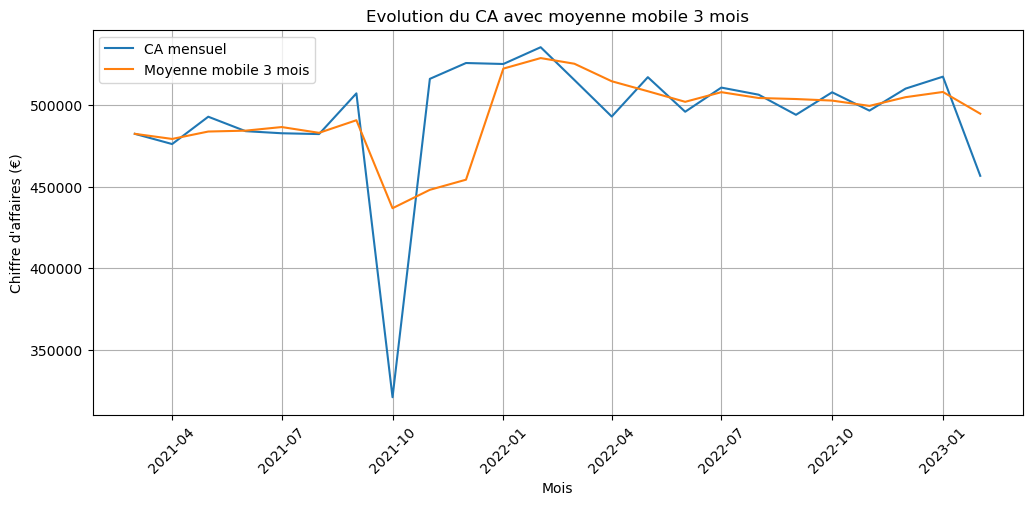

In [45]:
plt.figure(figsize=(12,5))

plt.plot(chiffre_daffaire["mois"], chiffre_daffaire["CA"], label="CA mensuel")
plt.plot(chiffre_daffaire["mois"], chiffre_daffaire["CA_mobile"], label="Moyenne mobile 3 mois")

plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires (€)")
plt.title("Evolution du CA avec moyenne mobile 3 mois")

plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.show()

In [46]:
# Il y a une anomalie en octobre 2021. Nous allons donc voir ce qu'il en est.
octobre_2021 = lapage[
    (lapage['date'].dt.year == 2021) &
    (lapage['date'].dt.month == 10)
]

display(octobre_2021)

,id_prod,date,session_id,client_id,price,categ,sex,birth,age,mois
68,0_1409,2021-10-02 17:39:26.919537,s_99013,c_5725,4.99,0,m,1975,46,2021-10
71,0_1247,2021-10-03 16:05:12.544172,s_99443,c_3394,15.99,0,f,1978,43,2021-10
80,0_1272,2021-10-13 14:35:01.163737,s_104207,c_8534,17.01,0,m,1988,33,2021-10
86,0_1102,2021-10-24 13:25:39.888945,s_109442,c_1609,4.63,0,m,1980,41,2021-10
93,0_1079,2021-10-05 21:57:27.673800,s_100557,c_7918,5.99,0,m,1987,34,2021-10
...,...,...,...,...,...,...,...,...,...,...
679422,0_1418,2021-10-22 01:12:51.848429,s_108264,c_7213,8.57,0,m,1979,42,2021-10
679440,0_1391,2021-10-26 04:40:29.252116,s_110243,c_7878,7.99,0,m,1989,32,2021-10
679490,0_1609,2021-10-15 16:58:58.818380,s_105230,c_6714,18.99,0,f,1968,53,2021-10
679515,0_1635,2021-10-01 23:19:52.888190,s_98649,c_1061,16.99,0,m,1991,30,2021-10


In [47]:
octobre_2021['categ'].unique()

array([0, 1, 2])

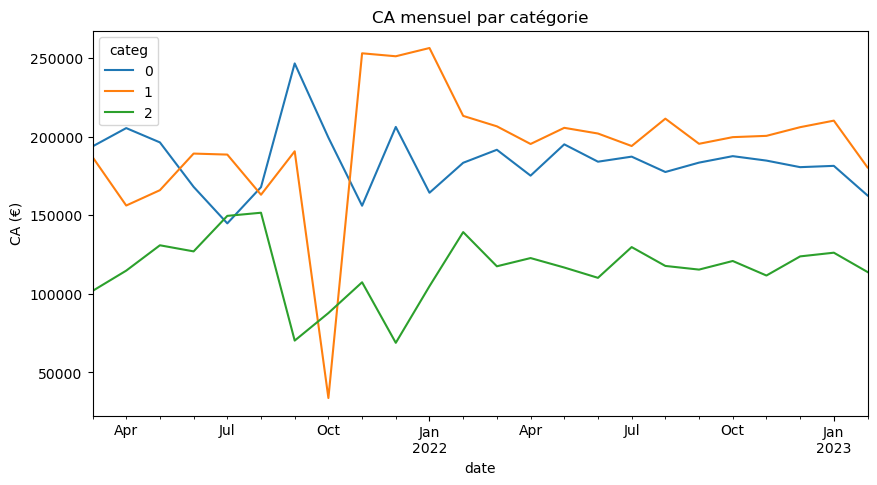

In [48]:
ca_categ = lapage.pivot_table(
    values='price',
    index=lapage['date'].dt.to_period('M'),
    columns='categ',
    aggfunc='sum'
)

ca_categ.plot(figsize=(10,5))
plt.title("CA mensuel par catégorie")
plt.ylabel("CA (€)")
plt.show()

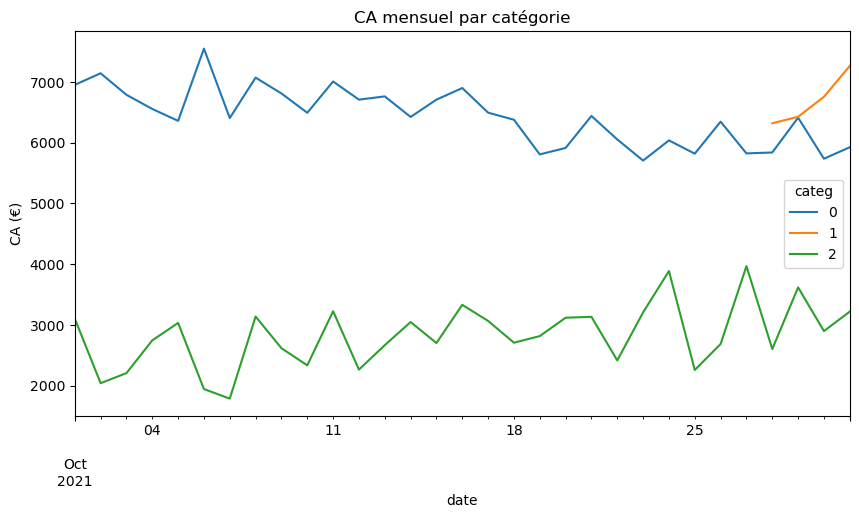

In [49]:
ca_categ_oct = octobre_2021.pivot_table(
    values='price',
    index=lapage['date'].dt.to_period('D'),
    columns='categ',
    aggfunc='sum'
)

ca_categ_oct.plot(figsize=(10,5))
plt.title("CA mensuel par catégorie")
plt.ylabel("CA (€)")
plt.show()

On remarque que les produits de catégorie 1 sont absents, ce qui explique la baisse du CA en octobre 2021.

In [128]:
lapage["date"] = pd.to_datetime(lapage["date"])

ca_journalier = (
    lapage
    .groupby("jour")["price"]
    .sum()
    .reset_index(name="CA")
)

ca_journalier["jour"] = pd.to_datetime(ca_journalier["jour"])
ca_journalier = ca_journalier.set_index("jour")

decomposition = seasonal_decompose(
    ca_journalier["CA"],
    model="additive",
    period=30
)

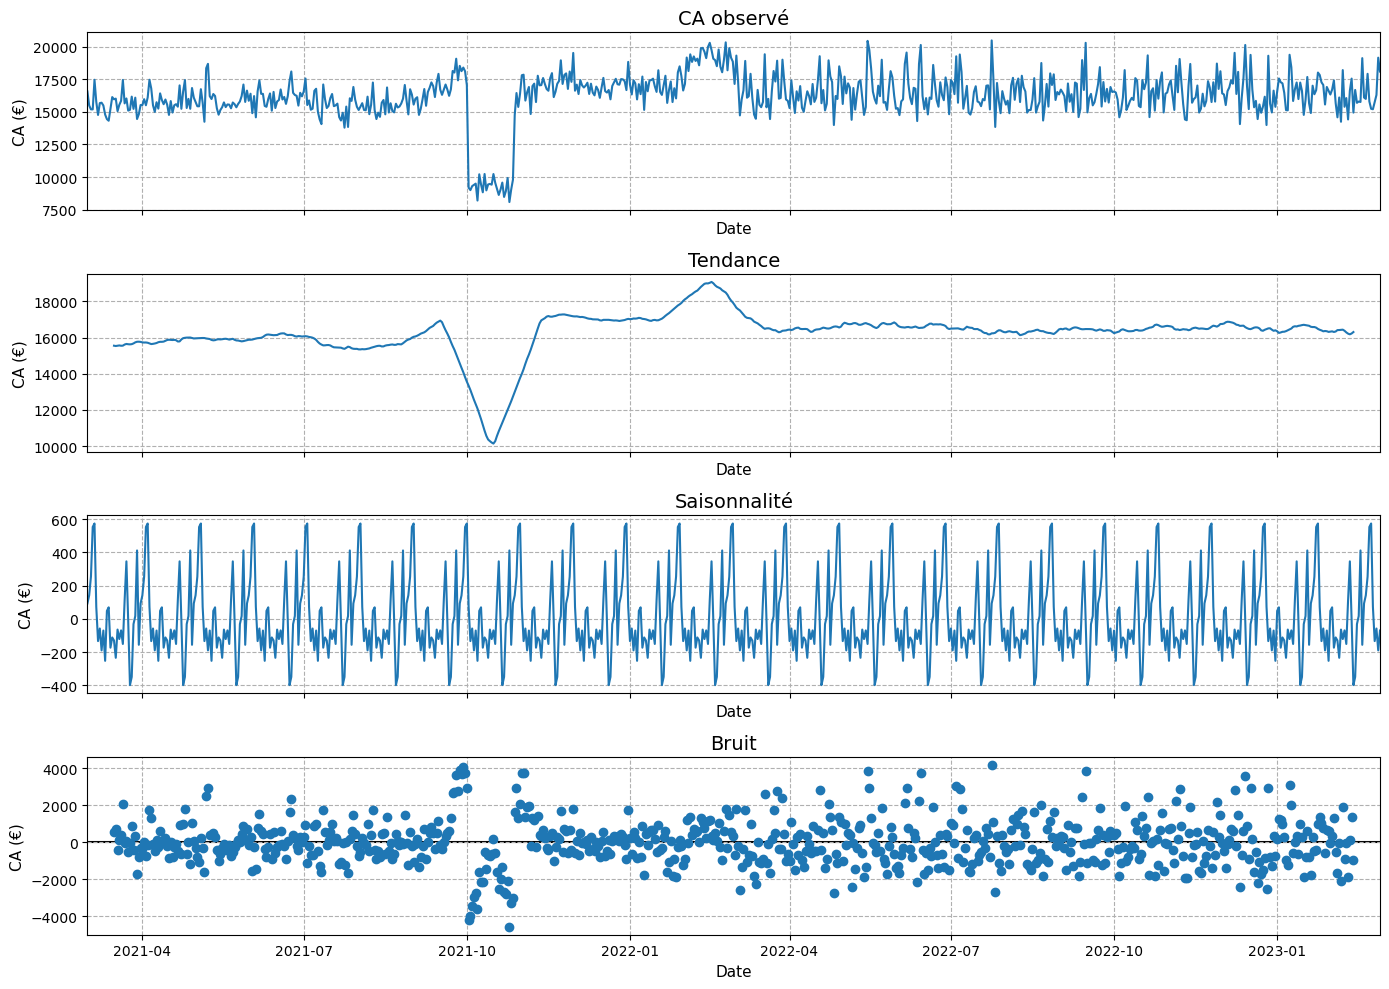

In [129]:
fig = decomposition.plot()
fig.set_size_inches(14, 10)

axes = fig.axes

titres = [
    "CA observé",
    "Tendance",
    "Saisonnalité",
    "Bruit"
]

for ax, titre in zip(axes, titres):
    ax.set_title(titre, fontsize=14)
    ax.set_xlabel("Date", fontsize=11)
    ax.set_ylabel("CA (€)", fontsize=11)
    ax.grid(True, linestyle="--")


plt.tight_layout()
plt.show()

### 2-2 : Chiffre d'affaires par catégorie

In [53]:
ca_categ = lapage.groupby("categ").agg(
    CA=("price", "sum"),
    nb_ventes=("price", "count"),
    prix_moyen=("price", "mean")
).reset_index()


In [54]:
ca_categ.head()

,categ,CA,nb_ventes,prix_moyen
0,0,4421938.76,415680,10.637843
1,1,4653722.69,227169,20.485730
2,2,2780275.02,36483,76.207412


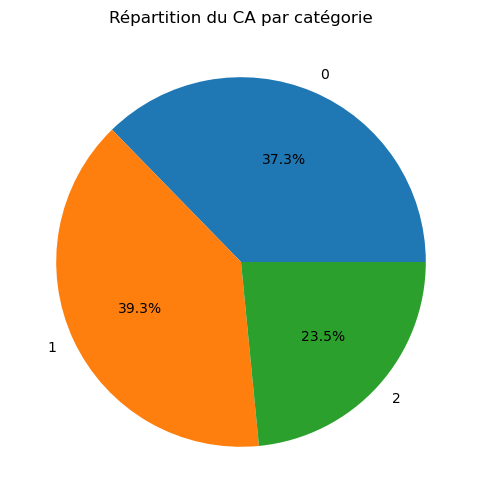

In [55]:
plt.figure(figsize=(6,6))

plt.pie(
    ca_categ["CA"],
    labels=ca_categ["categ"],
    autopct="%1.1f%%"
)

plt.title("Répartition du CA par catégorie")

plt.show()

### 2-3 : Nombre de clients par mois

In [56]:
lapage["mois"] = lapage["date"].dt.to_period("M")
lapage.head()

,id_prod,date,session_id,client_id,price,categ,sex,birth,age,mois
0,0_1518,2022-05-20 13:21:29.043970,s_211425,c_103,4.18,0,f,1986,36,2022-05
1,1_251,2022-02-02 07:55:19.149409,s_158752,c_8534,15.99,1,m,1988,34,2022-02
2,0_1277,2022-06-18 15:44:33.155329,s_225667,c_6714,7.99,0,f,1968,54,2022-06
3,2_209,2021-06-24 04:19:29.835891,s_52962,c_6941,69.99,2,m,2000,21,2021-06
4,0_1509,2023-01-11 08:22:08.194479,s_325227,c_4232,4.99,0,m,1980,43,2023-01


In [57]:
clients_mois = lapage.groupby("mois")["client_id"].nunique().reset_index()
clients_mois.columns = ["mois", "nb_clients"]

In [58]:
clients_mois.head()

,mois,nb_clients
0,2021-03,5676
1,2021-04,5674
2,2021-05,5644
3,2021-06,5659
4,2021-07,5672


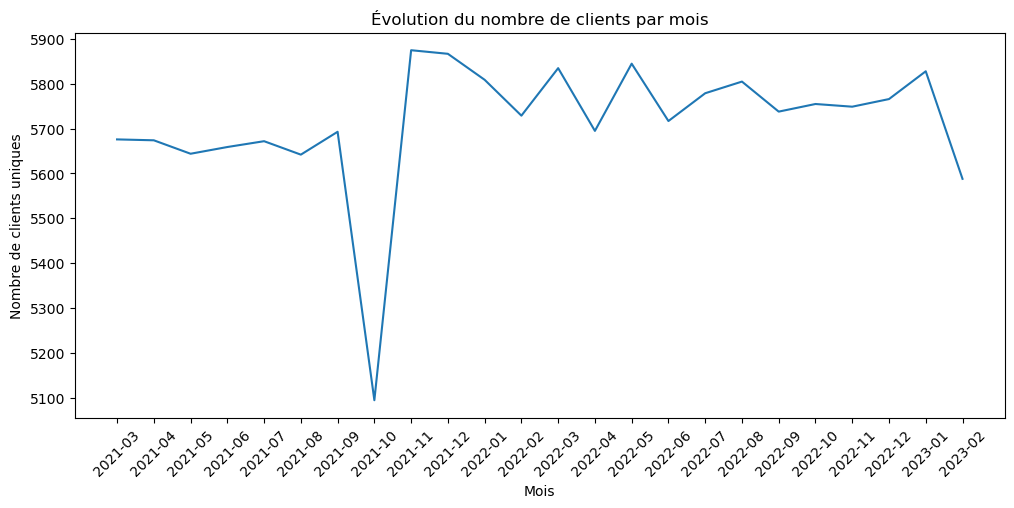

In [59]:
plt.figure(figsize=(12,5))

plt.plot(clients_mois["mois"].astype(str), clients_mois["nb_clients"])

plt.xlabel("Mois")
plt.ylabel("Nombre de clients uniques")
plt.title("Évolution du nombre de clients par mois")

plt.xticks(rotation=45)

plt.show()

### 2-4 : Nombre de transactions et de produits vendus

In [60]:
transactions_mois = lapage.groupby("mois")["session_id"].nunique().reset_index()
transactions_mois.columns = ["mois", "nb_transactions"]

In [61]:
produits_mois = lapage.groupby("mois").size().reset_index(name="nb_produits")

In [62]:
resume_mois = transactions_mois.merge(produits_mois, on="mois")
resume_mois.head()

,mois,nb_transactions,nb_produits
0,2021-03,14203,28610
1,2021-04,13972,28457
2,2021-05,14169,28293
3,2021-06,13839,26857
4,2021-07,13573,24742


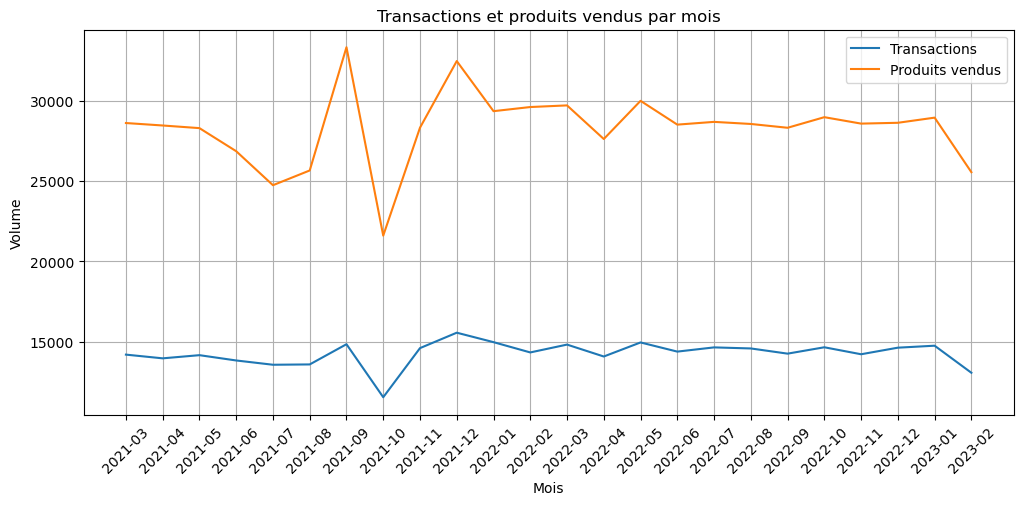

In [63]:
plt.figure(figsize=(12,5))

plt.plot(resume_mois["mois"].astype(str),
         resume_mois["nb_transactions"],
         label="Transactions")

plt.plot(resume_mois["mois"].astype(str),
         resume_mois["nb_produits"],
         label="Produits vendus")

plt.title("Transactions et produits vendus par mois")
plt.xlabel("Mois")
plt.ylabel("Volume")
plt.xticks(rotation=45)
plt.grid()
plt.legend()

plt.show()

## Partie 3 : Zoom sur les références

In [64]:
top_produits = lapage.groupby("id_prod")["price"].sum().sort_values(ascending=False).head(10)
flop_produits = lapage.groupby("id_prod")["price"].sum().sort_values().head(10)
flop_produits.head()

id_prod
0_1539    0.99
0_1284    1.38
0_1653    1.98
0_541     1.99
0_807     1.99
Name: price, dtype: float64

In [65]:
top_clients = lapage.groupby("client_id")["price"].sum().sort_values(ascending=False).head(10)


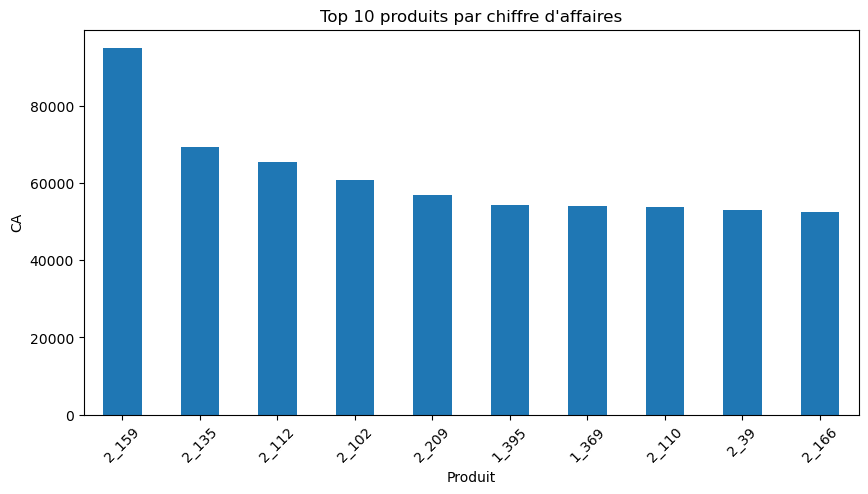

In [66]:
top_produits.plot(kind="bar", figsize=(10,5))

plt.title("Top 10 produits par chiffre d'affaires")
plt.xlabel("Produit")
plt.ylabel("CA")
plt.xticks(rotation=45)

plt.show()

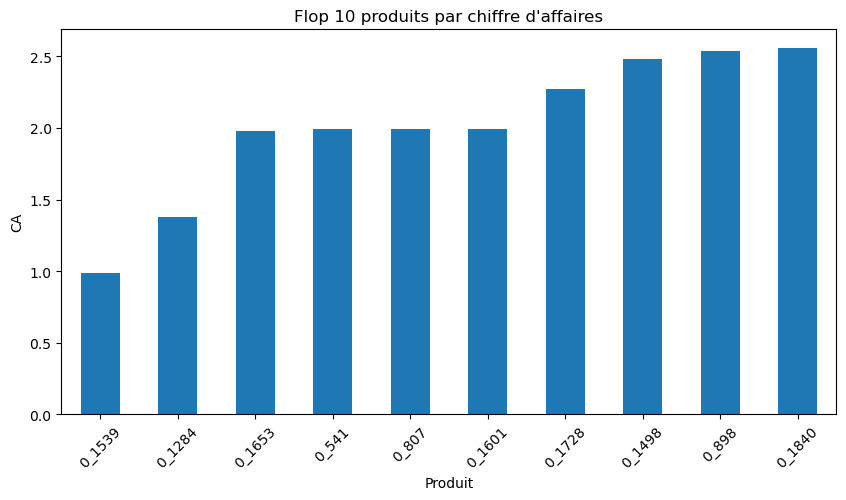

In [67]:
flop_produits.plot(kind="bar", figsize=(10,5))

plt.title("Flop 10 produits par chiffre d'affaires")
plt.xlabel("Produit")
plt.ylabel("CA")
plt.xticks(rotation=45)

plt.show()

In [68]:
top_products = lapage.groupby('id_prod')['id_prod'].count().sort_values(ascending=False).head(10)

print(top_products)

id_prod
1_369    2252
1_417    2189
1_414    2180
1_498    2128
1_425    2096
1_403    1960
1_412    1951
1_413    1945
1_406    1939
1_407    1935
Name: id_prod, dtype: int64


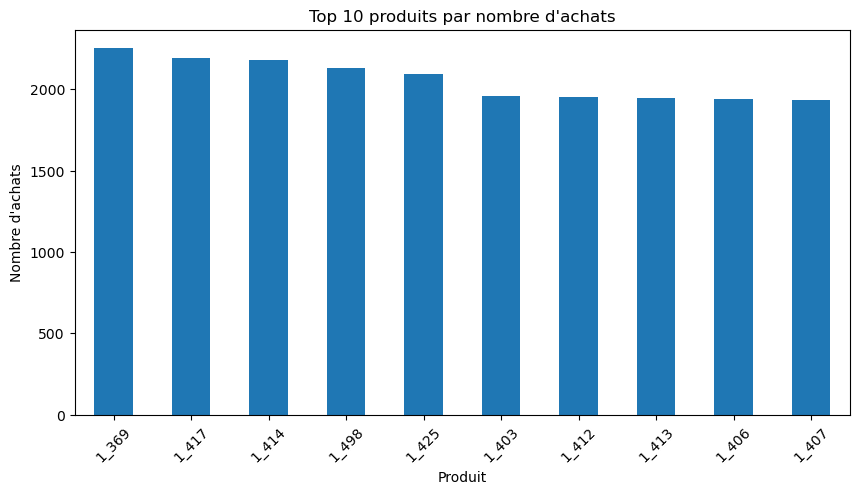

In [69]:
plt.figure(figsize=(10,5))

top_products.plot(
    kind='bar'
)

plt.title("Top 10 produits par nombre d'achats")
plt.xlabel("Produit")
plt.ylabel("Nombre d'achats")

plt.xticks(rotation=45)
plt.show()

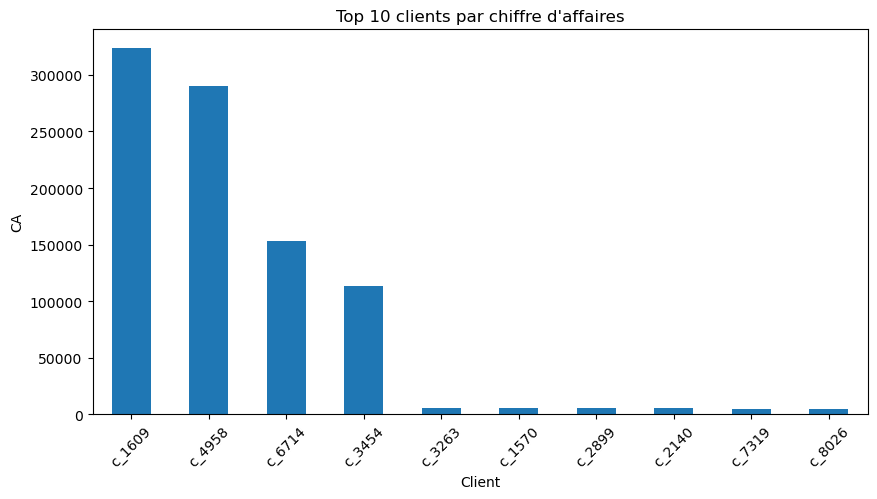

In [70]:
top_clients.plot(kind="bar", figsize=(10,5))

plt.title("Top 10 clients par chiffre d'affaires")
plt.xlabel("Client")
plt.ylabel("CA")
plt.xticks(rotation=45)

plt.show()

In [71]:
top_clients_nb = lapage.groupby("client_id")["price"].count().sort_values(ascending=False).head(10)

print(top_products)

id_prod
1_369    2252
1_417    2189
1_414    2180
1_498    2128
1_425    2096
1_403    1960
1_412    1951
1_413    1945
1_406    1939
1_407    1935
Name: id_prod, dtype: int64


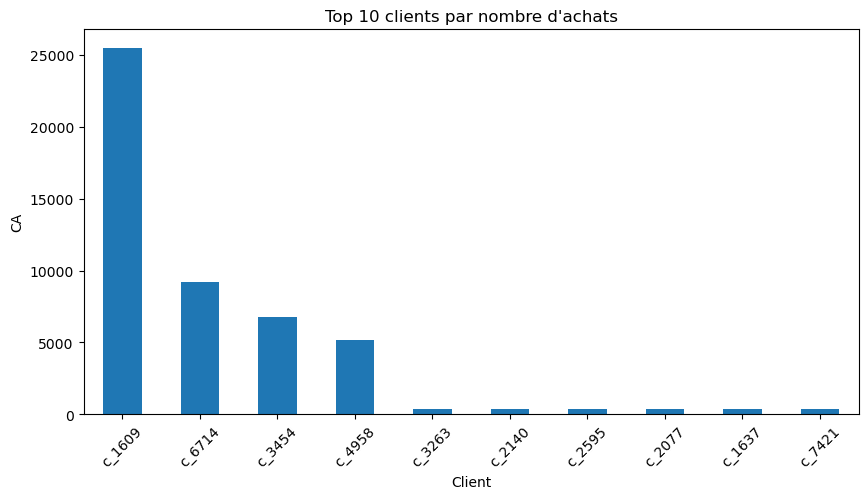

In [72]:
top_clients_nb.plot(kind="bar", figsize=(10,5))

plt.title("Top 10 clients par nombre d'achats")
plt.xlabel("Client")
plt.ylabel("CA")
plt.xticks(rotation=45)

plt.show()

In [73]:
sex_CA = lapage.groupby('sex')['price'].sum()

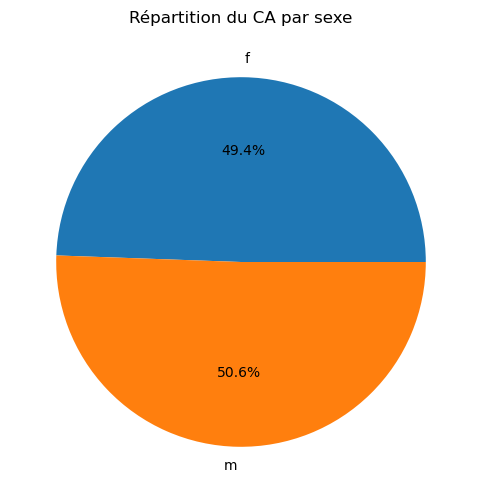

In [74]:
plt.figure(figsize=(6,6))

plt.pie(
    sex_CA.values,
    labels=sex_CA.index,
    autopct="%1.1f%%"
)

plt.title("Répartition du CA par sexe")
plt.show()

In [75]:
tranche_age = lapage.groupby(
    pd.cut(
        lapage['age'],
        bins=[0, 18, 25, 35, 50, 65, 100],
        labels=['<18', '18-25', '26-35', '36-50', '51-65', '65+'],
    ), observed=False
)['price'].sum()

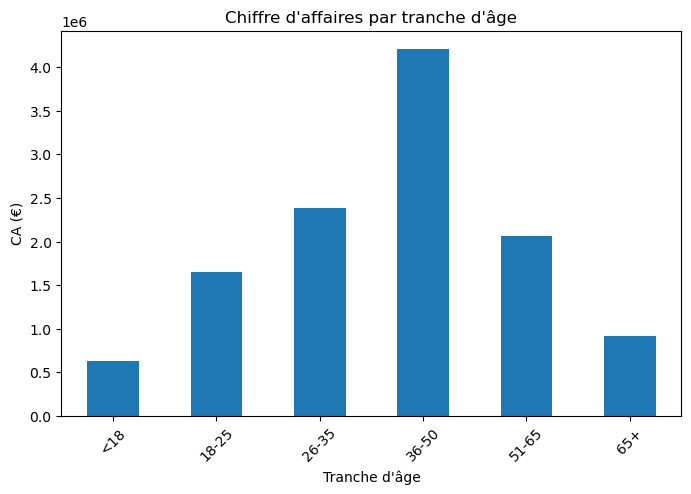

In [76]:
plt.figure(figsize=(8,5))

tranche_age.plot(
    kind='bar'
)

plt.title("Chiffre d'affaires par tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("CA (€)")

plt.xticks(rotation=45)

plt.show()

In [77]:
age_bins = pd.cut(
    lapage['age'],
    bins=[0, 18, 25, 35, 50, 65, 100],
    labels=['<18', '18-25', '26-35', '36-50', '51-65', '65+']
)

df_panier = (
    lapage.assign(tranche_age=age_bins)
          .groupby('session_id')
          .agg(
              panier=('price', 'sum'),
              tranche_age=('tranche_age', 'first')
          )
)

panier_moyen = (
    df_panier.groupby('tranche_age', observed=False)['panier']
    .mean()
    .reset_index()
)

panier_moyen.head()

,tranche_age,panier
0,<18,70.431945
1,18-25,71.995356
2,26-35,41.570313
3,36-50,31.493081
4,51-65,25.198950


In [78]:
df_panier = pd.DataFrame({
    'panier': panier_moyen['panier'],
    'tranche_age': panier_moyen['tranche_age']
})

<Figure size 800x500 with 0 Axes>

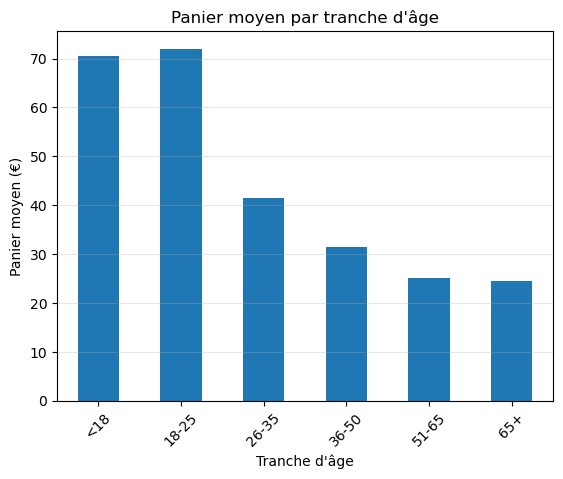

In [79]:
plt.figure(figsize=(8,5))

panier_moyen.plot(
    x='tranche_age',
    y='panier',
    kind='bar',
    legend=False
)
plt.title("Panier moyen par tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Panier moyen (€)")

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.show()

## Partie 3 - bis : Zoom sur les références sans les clients B2B

In [80]:
# On va créer un nouveau datafraphe sans les clients B&B
clients_bb = ['c_1609', 'c_6714', 'c_4958', 'c_3454']

lapage_clean = lapage[~lapage['client_id'].isin(clients_bb)]

In [81]:
print("Avant :", lapage.shape)
print("Après :", lapage_clean.shape)

Avant : (679332, 10)
Après : (632689, 10)


In [82]:
print(lapage['price'].sum())
print(lapage_clean['price'].sum())

11855936.469999999
10974816.02


In [83]:
top_clients_clean = lapage_clean.groupby("client_id")["price"].sum().sort_values(ascending=False).head(10)

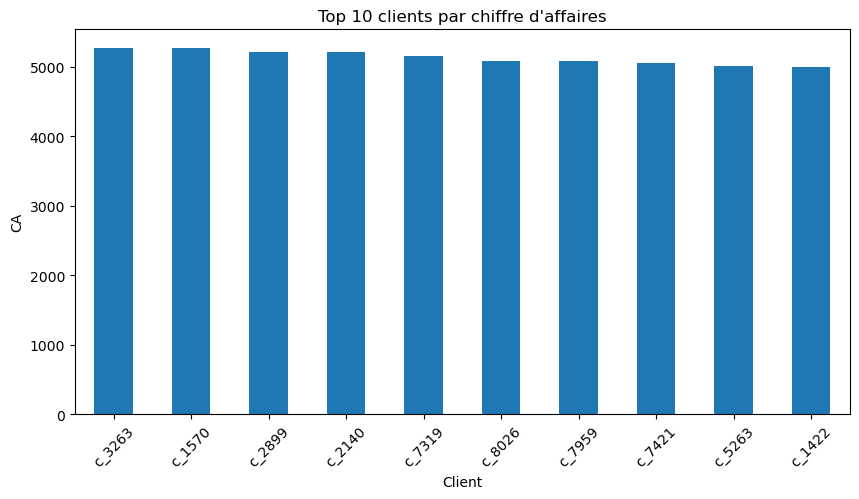

In [84]:
top_clients_clean.plot(kind="bar", figsize=(10,5))

plt.title("Top 10 clients par chiffre d'affaires")
plt.xlabel("Client")
plt.ylabel("CA")
plt.xticks(rotation=45)

plt.show()

In [85]:
tranche_age_clean = lapage_clean.groupby(
    pd.cut(
        lapage['age'],
        bins=[0, 18, 25, 35, 50, 65, 100],
        labels=['<18', '18-25', '26-35', '36-50', '51-65', '65+']
    ), observed=False
)['price'].sum()

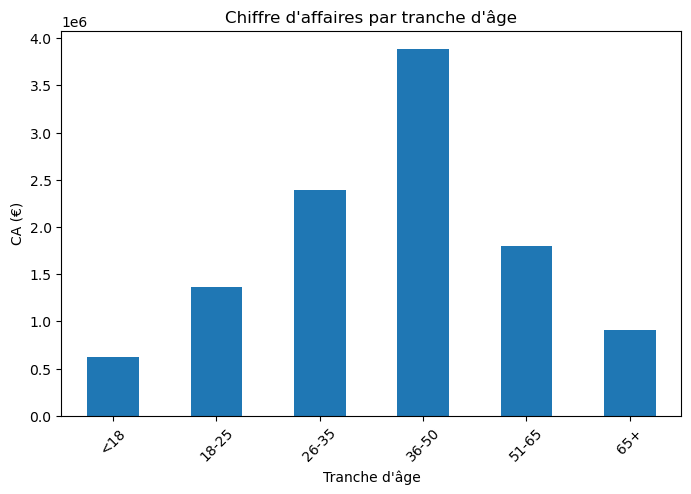

In [86]:
plt.figure(figsize=(8,5))

tranche_age_clean.plot(
    kind='bar'
)

plt.title("Chiffre d'affaires par tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("CA (€)")

plt.xticks(rotation=45)

plt.show()

In [87]:
age_bins_clean = pd.cut(
    lapage['age'],
    bins=[0, 18, 25, 35, 50, 65, 100],
    labels=['<18', '18-25', '26-35', '36-50', '51-65', '65+']
)

df_panier_clean = (
    lapage.assign(tranche_age=age_bins_clean)
          .groupby('session_id')
          .agg(
              panier=('price', 'sum'),
              tranche_age=('tranche_age', 'first')
          )
)

panier_moyen_clean = (
    df_panier_clean.groupby('tranche_age', observed=False)['panier']
    .mean()
    .reset_index()
)

panier_moyen_clean.head()

,tranche_age,panier
0,<18,70.431945
1,18-25,71.995356
2,26-35,41.570313
3,36-50,31.493081
4,51-65,25.198950


In [88]:
df_panier_clean = pd.DataFrame({
    'panier': panier_moyen_clean['panier'],
    'tranche_age': panier_moyen_clean['tranche_age']
})

In [89]:
panier_moyen_clean = df_panier_clean.groupby('tranche_age', observed=False)['panier'].mean()

print(panier_moyen_clean)

tranche_age
<18      70.431945
18-25    71.995356
26-35    41.570313
36-50    31.493081
51-65    25.198950
65+      24.407006
Name: panier, dtype: float64


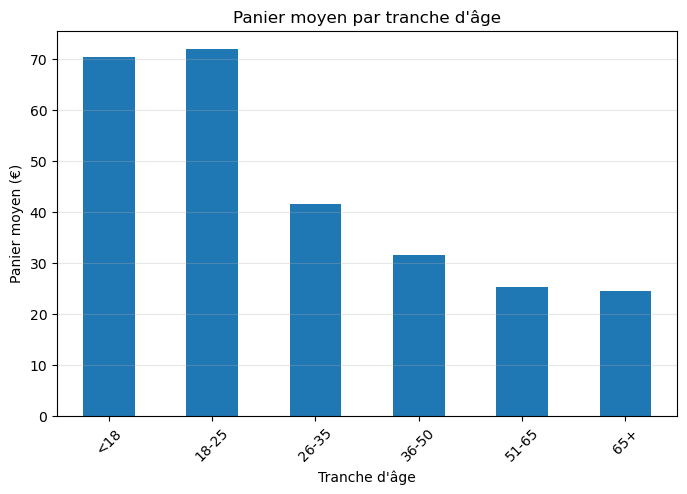

In [90]:
plt.figure(figsize=(8,5))

panier_moyen_clean.sort_index().plot(kind='bar')

plt.title("Panier moyen par tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Panier moyen (€)")

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.show()

## Partie 4 : Profil des clients

### 4-1 : Répartition du chiffre d'affaires pour les clients BtoB

In [91]:
b2b_df = lapage[lapage['client_id'].isin(clients_bb)]

In [92]:
ca_bb = b2b_df['price'].sum()

print(f"CA BtoB : {ca_bb:.2f} €")

CA BtoB : 881120.45 €


In [93]:
ca_bb_par_client = b2b_df.groupby('client_id')['price'].sum()

print(ca_bb_par_client)

client_id
c_1609    324033.35
c_3454    113667.90
c_4958    289760.34
c_6714    153658.86
Name: price, dtype: float64


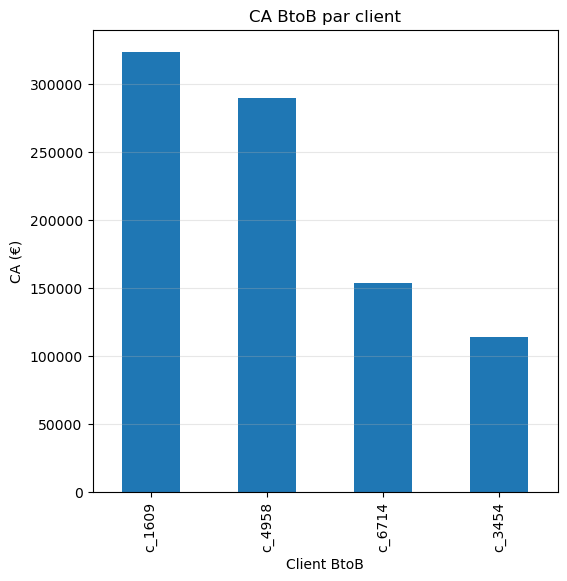

In [94]:
plt.figure(figsize=(6,6))

ca_bb_par_client.sort_values(ascending=False).plot(
    kind='bar'
)

plt.title("CA BtoB par client")
plt.xlabel("Client BtoB")
plt.ylabel("CA (€)")
plt.grid(axis='y', alpha=0.3)

plt.show()

In [95]:
part_bb = ca_bb / ca_total * 100

print(f"Part du CA B2B : {part_bb:.2f}%")

Part du CA B2B : 7.43%


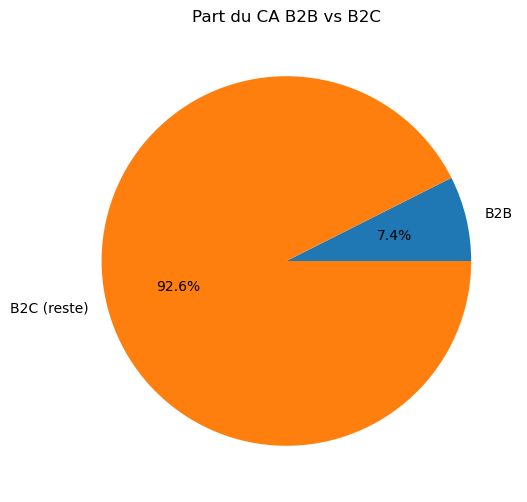

In [96]:
plt.figure(figsize=(6,6))

plt.pie(
    [ca_bb, ca_total - ca_bb],
    labels=['B2B', 'B2C (reste)'],
    autopct="%1.1f%%"
)

plt.title("Part du CA B2B vs B2C")

plt.show()

### 4-2 : Courbe de Lorenz

In [97]:
ca_clients = lapage.groupby('client_id')['price'].sum().sort_values()

In [98]:
# Valeurs cumulées
valeurs = ca_clients.values
cum_valeurs = np.cumsum(valeurs)

# Normalisation
cum_valeurs = cum_valeurs / cum_valeurs[-1]
cum_clients = np.arange(1, len(valeurs) + 1) / len(valeurs)

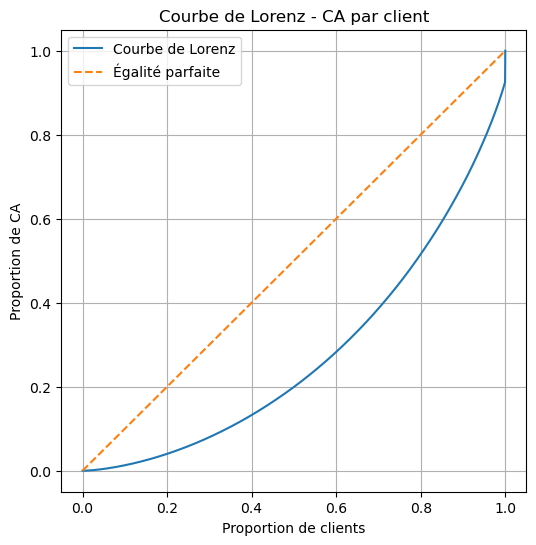

In [99]:
plt.figure(figsize=(6,6))

# Courbe de Lorenz
plt.plot(cum_clients, cum_valeurs, label="Courbe de Lorenz")

# Droite d’égalité parfaite
plt.plot([0,1], [0,1], linestyle="--", label="Égalité parfaite")

plt.title("Courbe de Lorenz - CA par client")
plt.xlabel("Proportion de clients")
plt.ylabel("Proportion de CA")
plt.legend()

plt.grid()
plt.show()

In [100]:
# Courbe de Lorenz sans les clients B2B

ca_clients_clean = lapage_clean.groupby('client_id')['price'].sum().sort_values()

In [101]:
# Valeurs cumulées
valeurs_clean = ca_clients_clean.values
cum_valeurs_clean = np.cumsum(valeurs_clean)

# Normalisation
cum_valeurs_clean = cum_valeurs_clean / cum_valeurs_clean[-1]
cum_clients_clean = np.arange(1, len(valeurs_clean) + 1) / len(valeurs_clean)

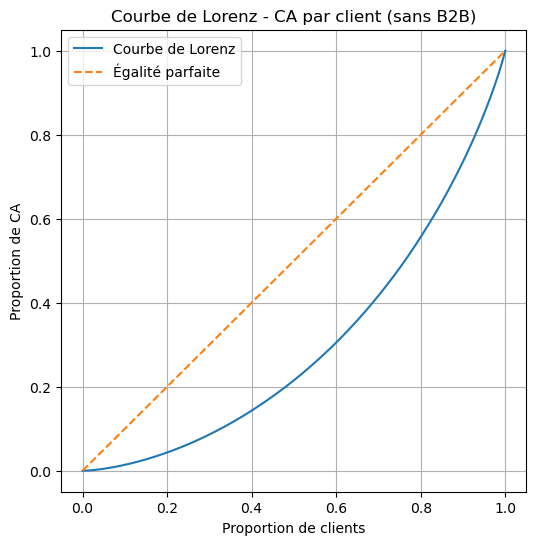

In [102]:
plt.figure(figsize=(6,6))

# Courbe de Lorenz
plt.plot(cum_clients_clean, cum_valeurs_clean, label="Courbe de Lorenz")

# Droite d’égalité parfaite
plt.plot([0,1], [0,1], linestyle="--", label="Égalité parfaite")

plt.title("Courbe de Lorenz - CA par client (sans B2B)")
plt.xlabel("Proportion de clients")
plt.ylabel("Proportion de CA")
plt.legend()

plt.grid()
plt.show()